# Asistente inteligente de cronogramas
## Predicción de retrasos en tareas de proyectos mediante Machine Learning

**Maestría en Inteligencia Artificial, Educación e Investigación · Curso: Machine Learning**
**Autora:** Sheila De Oleo

---

### Problemática
En la gestión de proyectos, los cronogramas suelen construirse con duraciones estimadas "a ojo" y los riesgos de atraso se detectan cuando ya ocurrieron. El *CHAOS Report* del Standish Group ha reportado de forma consistente que una proporción importante de proyectos de software termina fuera de plazo. Un gerente de proyecto necesita saber **con anticipación** qué tareas tienen mayor probabilidad de atrasarse, **cuántos días** podría ser el atraso y **qué impacto** tendría sobre la fecha final.

### Objetivo general
Desarrollar un modelo de Machine Learning que prediga el riesgo y la magnitud del atraso de las tareas de un proyecto, a partir de sus características al momento de asignarles una fecha límite, e integrarlo en un prototipo web que apoye la gestión de cronogramas.

### Objetivos específicos
1. Caracterizar un conjunto de datos real de tareas con fecha límite e identificar los factores asociados al atraso.
2. Entrenar y comparar modelos de **clasificación** (¿se atrasará?) y **regresión** (¿cuántos días?).
3. Evaluar los modelos con validación temporal y métricas adecuadas al desbalance de clases.
4. Interpretar los factores de riesgo con valores SHAP.
5. Integrar los modelos en una aplicación que simule el cronograma y priorice las tareas críticas.

### Estructura del cuaderno
1. Carga de datos · 2. Calidad y preprocesamiento · 3. Análisis exploratorio · 4. Preparación para el modelado · 5. Modelo 1: clasificación · 6. Interpretación (SHAP) · 7. Modelo 2: regresión · 8. Análisis de robustez · 9. Exportación de modelos · 10. Aplicación a un cronograma · 11. Conclusiones

In [1]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
from scipy.stats import spearmanr

from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.dummy import DummyClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, accuracy_score, confusion_matrix, roc_curve,
                             precision_recall_curve, brier_score_loss, mean_absolute_error,
                             median_absolute_error, mean_squared_error, r2_score)
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.features import (cargar_datos, limpiar, matriz_modelo, COLUMNAS_MODELO,
                          VARIABLES_NUMERICAS, DESCRIPCION, nombre_legible, PRIORIDAD_ES)

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MOD = ROOT / "models"; MOD.mkdir(exist_ok=True)
SEMILLA = 42

# Estilo de gráficos (paleta validada para daltonismo)
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": "#0b0b0b",
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})
def guardar(nombre):
    plt.savefig(FIG / f"{nombre}.png"); plt.show()
print("Raíz del proyecto:", ROOT)

Raíz del proyecto: /home/claude/proyecto


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Carga de datos

**Origen:** conjunto de datos público de Choetkiertikul, Dam, Tran y Ghose (2017), *Predicting the delay of issues with due dates in software projects* (Empirical Software Engineering, 22(3), 1223–1263). Disponible en `github.com/SEAnalytics/datasets` (carpeta *delayed issues/EMSE2017*).

Contiene **tareas reales con fecha límite** de los sistemas de gestión (JIRA) de 8 organizaciones: Apache, Duraspace, Java.net, JBoss, JIRA, Moodle, Mulesoft y WSO2. Usamos la versión `*_due.csv`, donde las variables se midieron **en el momento en que se asignó la fecha límite a la tarea**. Ese es justo el momento en que un gerente arma o actualiza su cronograma, y además evita usar información del futuro (fuga de datos).

In [2]:
crudo = cargar_datos(ROOT / "data" / "raw")
print(f"Registros: {crudo.shape[0]:,} · Columnas: {crudo.shape[1]}")
crudo.head()

Registros: 64,747 · Columnas: 27


,issuekey,delaydays,openeddate,type,discussion,repetition,perofdelay,workload,priority,no_comment,...,reporterrep,no_des_change,ProgressTime,RemainingDay,topic_10,topic_100,topic_200,topic_300,topic_400,proyecto
0,DIR-1,0,2004-01-26 00:00:00,Task,0,0,0,1,Critical,0,...,0.0,0,0,35,6,26,40,219,132,apache
1,DIRSERVER-10,72,2004-01-26 00:00:00,Bug,0,0,0,1,Critical,0,...,0.0,0,0,5,9,54,167,254,275,apache
2,OPENEJB-1,0,2004-01-28 00:00:00,NewFeature,0,0,0,0,Major,2,...,0.0,0,0,971,2,90,191,298,293,apache
3,JAMES-149,529,2004-02-08 00:00:00,Task,0,2,0,1,Minor,0,...,0.0,0,0,20,2,36,140,294,367,apache
4,JAMES-150,0,2004-02-09 00:00:00,Bug,0,1,100,2,Major,2,...,0.5,1,0,4,7,64,181,211,12,apache


In [3]:
resumen = (crudo.groupby("proyecto")
           .agg(tareas=("issuekey", "size"),
                pct_atrasadas=("delaydays", lambda s: round((s > 0).mean() * 100, 1)),
                desde=("openeddate", "min"), hasta=("openeddate", "max")))
resumen

,tareas,pct_atrasadas,desde,hasta
proyecto,,,,
apache,6289,41.4,2004-01-26 00:00:00,2016-03-11 00:00:00
duraspace,3676,26.4,2007-03-17 00:00:00,2015-06-16 00:00:00
javanet,16326,16.0,2009-10-27 00:00:00,2016-03-18 00:00:00
jboss,3526,53.9,2004-04-16 00:00:00,2016-03-02 00:00:00
jira,4428,28.4,2004-08-25 00:00:00,2015-11-09 00:00:00
moodle,17004,11.2,2010-01-01 00:00:00,2016-03-14 00:00:00
mulesoft,8269,16.1,2010-01-03 00:00:00,2016-03-01 00:00:00
wso2,5229,23.7,2006-11-09 00:00:00,2016-02-03 00:00:00


## 2. Calidad de datos y preprocesamiento

Decisiones tomadas:

| Problema | Tratamiento | Justificación |
|---|---|---|
| Nombres técnicos en inglés | Traducción a lenguaje de gestión de proyectos | Interpretabilidad para el usuario final |
| 44 tipos de tarea distintos (muchos con < 0.5 %) | Agrupación en 9 categorías | Evita categorías raras que no generalizan |
| Prioridad textual con escalas distintas por organización | Escala ordinal 1–5; vacíos → 3 (media) | La prioridad tiene orden natural |
| `% atrasos del responsable` con valores > 100 | Recorte a [0, 100] | Un porcentaje no puede superar 100 (error de registro) |
| Variables `topic_*` (temas LDA de la descripción) | Se excluyen | No se pueden calcular sobre un cronograma nuevo sin el texto y el modelo LDA original |

**Variables objetivo:**
- `atrasada` (0/1): la tarea se cerró después de su fecha límite → **clasificación**.
- `dias_atraso`: cuántos días se pasó de la fecha límite → **regresión** (solo para tareas atrasadas).

In [4]:
print("Valores nulos por columna:"); print(crudo.isna().sum()[crudo.isna().sum() > 0])
print("\nRegistros duplicados:", crudo.duplicated().sum())
print("% de atrasos del responsable > 100:", f"{(crudo.perofdelay > 100).mean():.1%}")
df = limpiar(crudo).sort_values("fecha_creacion").reset_index(drop=True)
print("\nDataset limpio:", df.shape)
pd.DataFrame({"variable": list(DESCRIPCION), "descripción": list(DESCRIPCION.values())})

Valores nulos por columna:


priority    2292
dtype: int64

Registros duplicados: 0
% de atrasos del responsable > 100: 3.7%

Dataset limpio: (64747, 21)


,variable,descripción
0,prioridad,Prioridad de la tarea (1 = trivial ... 5 = blo...
1,dias_hasta_fecha_limite,Días que faltan para la fecha límite comprometida
2,dias_desde_creacion,Días transcurridos desde que se creó la tarea
3,carga_responsable,Tareas abiertas asignadas al responsable
4,pct_atrasos_responsable,% histórico de tareas atrasadas del responsable
5,predecesoras,Tareas de las que depende (la bloquean)
6,tareas_que_bloquea,Tareas que dependen de esta
7,tareas_relacionadas,Total de tareas vinculadas
8,reaperturas,Veces que la tarea se reabrió (retrabajo)
9,comentarios,Comentarios registrados en la tarea


In [5]:
df[VARIABLES_NUMERICAS + ["dias_atraso"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
prioridad,64747.0,3.00,0.92,1.0,2.0,3.0,3.0,5.0
dias_hasta_fecha_limite,64747.0,87.56,198.20,0.0,7.0,28.0,79.0,3328.0
dias_desde_creacion,64747.0,51.61,190.32,0.0,0.0,0.0,13.0,3036.0
carga_responsable,64747.0,26.46,57.74,0.0,5.0,12.0,28.0,853.0
pct_atrasos_responsable,64747.0,19.81,26.87,0.0,2.0,9.0,24.0,100.0
predecesoras,64747.0,0.05,0.44,0.0,0.0,0.0,0.0,36.0
tareas_que_bloquea,64747.0,0.03,0.25,0.0,0.0,0.0,0.0,26.0
tareas_relacionadas,64747.0,0.48,1.40,0.0,0.0,0.0,1.0,108.0
reaperturas,64747.0,0.43,1.17,0.0,0.0,0.0,0.0,37.0
comentarios,64747.0,2.54,6.18,0.0,0.0,1.0,2.0,221.0


## 3. Análisis exploratorio de datos (EDA)

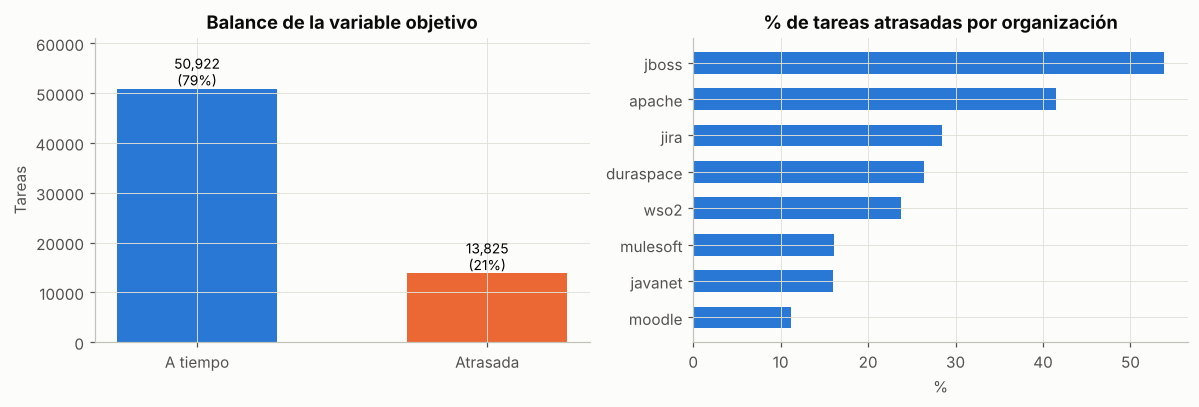

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
cnt = df.atrasada.value_counts().sort_index()
ax[0].bar(["A tiempo", "Atrasada"], cnt.values, color=[AZUL, NARANJA], width=0.55)
for i, v in enumerate(cnt.values):
    ax[0].text(i, v, f"{v:,}\n({v/len(df):.0%})", ha="center", va="bottom", fontsize=9)
ax[0].set_title("Balance de la variable objetivo"); ax[0].set_ylabel("Tareas"); ax[0].set_ylim(0, cnt.max()*1.2)
tasa = df.groupby("proyecto").atrasada.mean().sort_values()
ax[1].barh(tasa.index, tasa.values*100, color=AZUL, height=0.6)
ax[1].set_title("% de tareas atrasadas por organización"); ax[1].set_xlabel("%")
plt.tight_layout(); guardar("01_balance_y_proyectos")

**Lectura:** 21 % de las tareas se atrasaron, así que el problema es **desbalanceado**. Por eso no basta con la exactitud (*accuracy*): un modelo que diga siempre "a tiempo" acertaría el 79 %. Usaremos ROC-AUC, PR-AUC, F1 y *recall*. La tasa varía mucho entre organizaciones (11 % en Moodle frente a 54 % en JBoss), lo que muestra que la **cultura y la forma de trabajar** de cada equipo influyen.

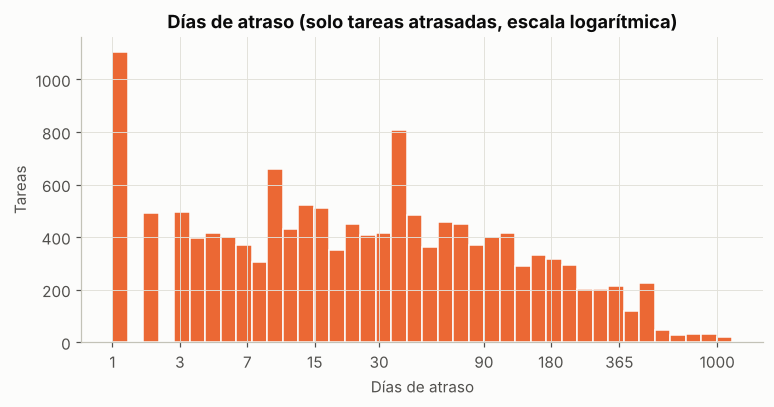

count    13825.0
mean        73.4
std        124.9
min          1.0
25%          7.0
50%         25.0
75%         80.0
90%        205.0
max       1169.0
Name: dias_atraso, dtype: float64


In [7]:
atr = df[df.atrasada == 1].dias_atraso
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(np.log1p(atr), bins=40, color=NARANJA, edgecolor="#fcfcfb")
ticks = [1, 3, 7, 15, 30, 90, 180, 365, 1000]
ax.set_xticks(np.log1p(ticks)); ax.set_xticklabels(ticks)
ax.set_title("Días de atraso (solo tareas atrasadas, escala logarítmica)")
ax.set_xlabel("Días de atraso"); ax.set_ylabel("Tareas")
guardar("02_distribucion_atraso")
print(atr.describe(percentiles=[.25, .5, .75, .9]).round(1))

**Lectura:** la distribución de días de atraso es muy **asimétrica**: la mediana es de 25 días, pero hay casos de más de un año. Por eso el modelo de regresión se entrena sobre `log(1 + días)`, lo que reduce la influencia de los valores extremos.

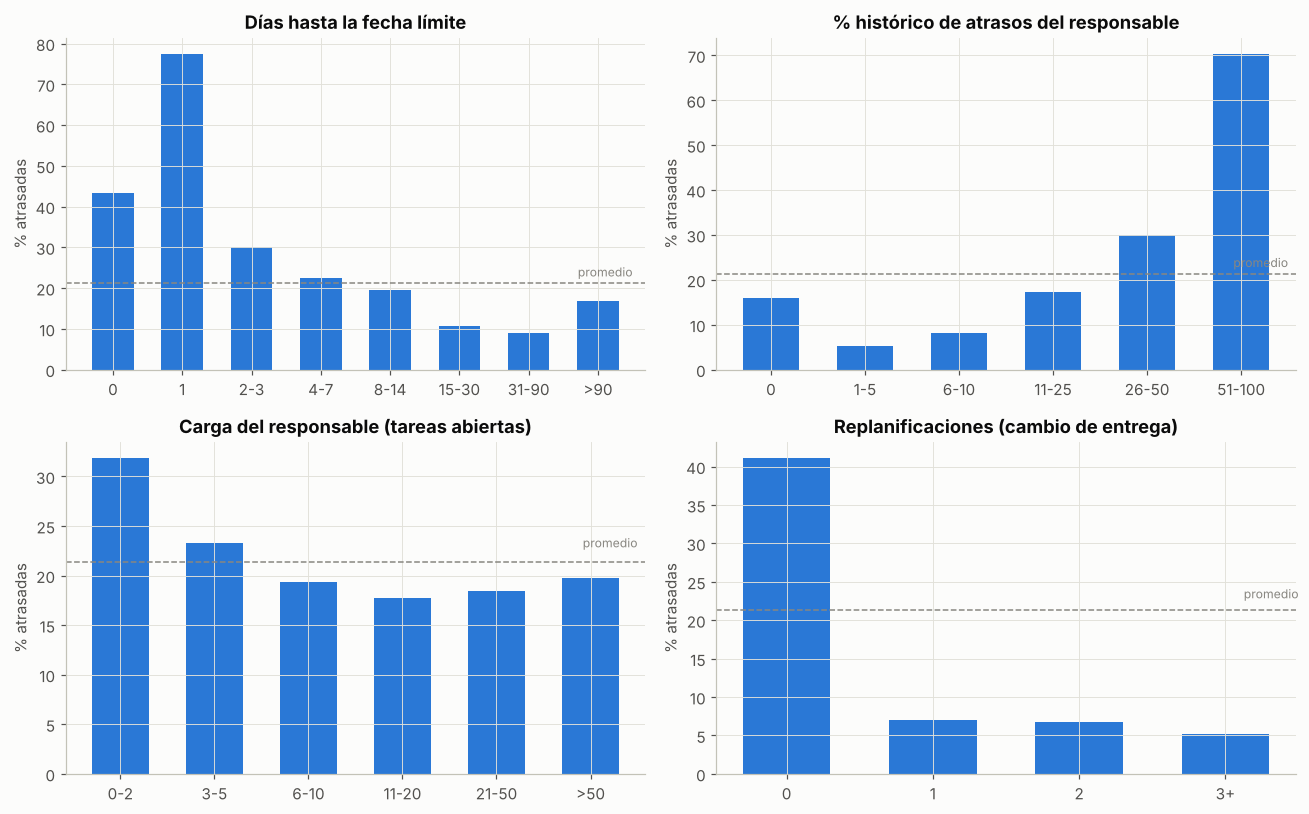

In [8]:
def tasa_por_rango(col, cortes, etiquetas):
    g = df.groupby(pd.cut(df[col], cortes, labels=etiquetas), observed=True).atrasada
    return g.mean()*100, g.size()

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
configs = [
    ("dias_hasta_fecha_limite", [-1, 0, 1, 3, 7, 14, 30, 90, 1e5], ["0", "1", "2-3", "4-7", "8-14", "15-30", "31-90", ">90"], "Días hasta la fecha límite"),
    ("pct_atrasos_responsable", [-1, 0, 5, 10, 25, 50, 100], ["0", "1-5", "6-10", "11-25", "26-50", "51-100"], "% histórico de atrasos del responsable"),
    ("carga_responsable", [-1, 2, 5, 10, 20, 50, 1e5], ["0-2", "3-5", "6-10", "11-20", "21-50", ">50"], "Carga del responsable (tareas abiertas)"),
    ("replanificaciones", [-1, 0, 1, 2, 1e5], ["0", "1", "2", "3+"], "Replanificaciones (cambio de entrega)"),
]
for ax, (col, cortes, etq, titulo) in zip(axes.flat, configs):
    t, n = tasa_por_rango(col, cortes, etq)
    ax.bar(t.index.astype(str), t.values, color=AZUL, width=0.6)
    ax.axhline(df.atrasada.mean()*100, color=GRIS, ls="--", lw=1)
    ax.text(len(t)-0.5, df.atrasada.mean()*100+1.5, "promedio", color=GRIS, ha="right", fontsize=8)
    ax.set_title(titulo); ax.set_ylabel("% atrasadas")
plt.tight_layout(); guardar("03_factores_riesgo")

**Hallazgos principales del EDA:**
- **Fechas límite muy cercanas** (0 a 1 día) tienen hasta 77 % de atraso. Comprometer fechas sin holgura es un factor de riesgo directo. Los compromisos a más de 90 días también suben un poco: los plazos largos tienden a "olvidarse".
- **El historial del responsable** importa: quienes han atrasado más del 50 % de sus tareas vuelven a atrasarse en el 70 % de los casos.
- **Resultado contraintuitivo 1 – Replanificaciones:** las tareas que **nunca** se movieron de entrega se atrasan mucho más (41 %) que las replanificadas (≈7 %). La explicación más razonable es que replanificar es una señal de **seguimiento activo**: alguien está mirando la tarea y ajusta el plan. Las tareas que nadie toca son las que se olvidan.
- **Resultado contraintuitivo 2 – Carga del responsable:** los responsables con muy pocas tareas abiertas (0–2) se atrasan más. En proyectos open source suelen ser colaboradores ocasionales, menos dedicados al proyecto que los colaboradores centrales.

> Estos resultados recuerdan que **correlación no es causalidad**: no significa que replanificar o sobrecargar a alguien *cause* puntualidad. Las variables funcionan como **indicadores** del nivel de atención y compromiso con la tarea.

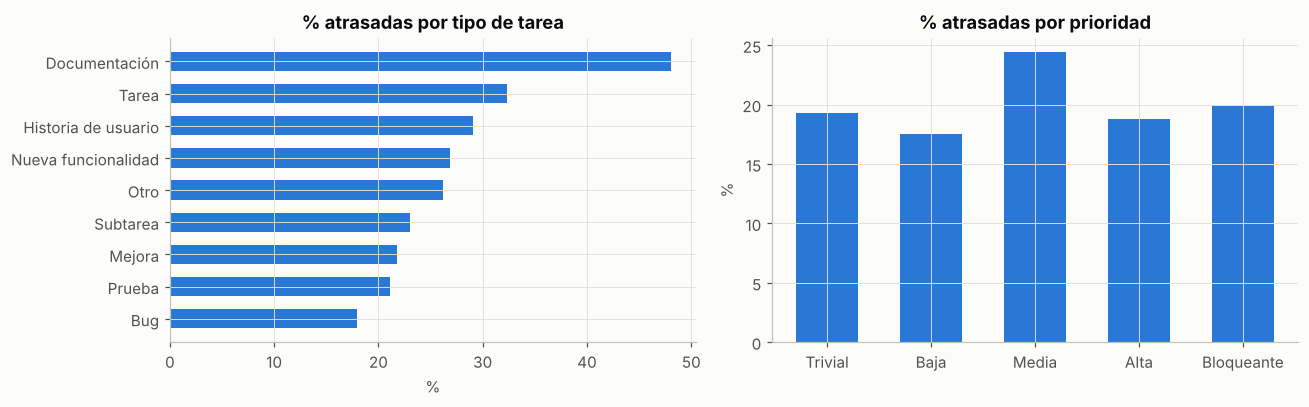

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
t = df.groupby("tipo").atrasada.agg(["mean", "size"]).query("size > 100").sort_values("mean")
ax[0].barh(t.index, t["mean"]*100, color=AZUL, height=0.6); ax[0].set_title("% atrasadas por tipo de tarea"); ax[0].set_xlabel("%")
p = df.groupby("prioridad").atrasada.mean()*100
ax[1].bar([PRIORIDAD_ES[i] for i in p.index], p.values, color=AZUL, width=0.6); ax[1].set_title("% atrasadas por prioridad"); ax[1].set_ylabel("%")
plt.tight_layout(); guardar("04_tipo_prioridad")

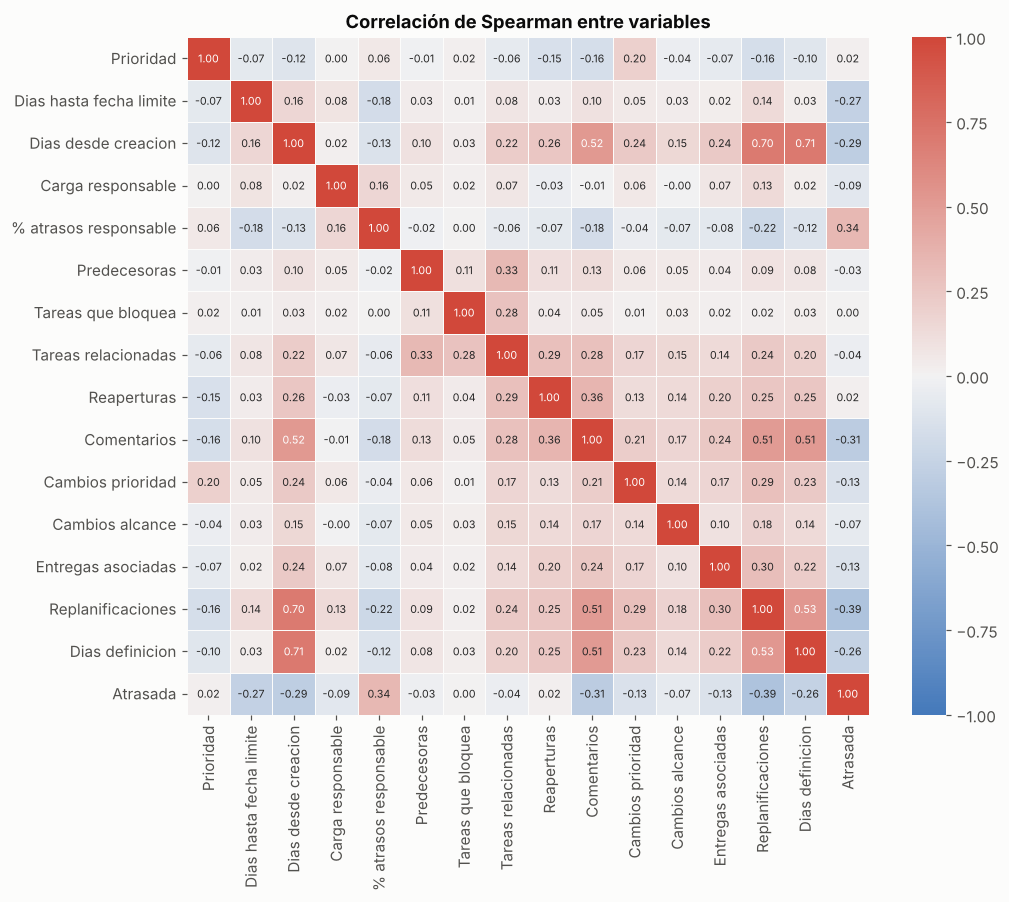

In [10]:
corr = df[VARIABLES_NUMERICAS + ["atrasada"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap=sns.diverging_palette(250, 15, s=75, l=50, as_cmap=True), center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5, linecolor="#fcfcfb",
            xticklabels=[nombre_legible(c) for c in corr.columns], yticklabels=[nombre_legible(c) for c in corr.columns], ax=ax)
ax.set_title("Correlación de Spearman entre variables"); ax.grid(False)
guardar("05_correlaciones")

**Lectura:** no hay correlaciones extremas entre predictoras (multicolinealidad baja), salvo `tareas relacionadas` con sus componentes (predecesoras / que bloquea), lo cual es esperable. Se usa Spearman porque las variables son conteos asimétricos.

## 4. Preparación para el modelado

**Validación temporal.** Como el modelo se usará para predecir tareas **futuras**, se ordenan las tareas por fecha de creación:
- **Entrenamiento (80 %)**: tareas más antiguas, hasta abril de 2014.
- **Prueba (20 %)**: tareas más recientes, que el modelo nunca vio.

Dentro del entrenamiento, los modelos se comparan con **validación cruzada temporal** (`TimeSeriesSplit`, 4 particiones): cada partición entrena con el pasado y valida con el periodo siguiente. Esto es más exigente y realista que una división aleatoria.

**Transformaciones:** las variables de tipo de tarea se codifican con *one-hot*. Para la regresión logística y Ridge se aplica `log(1+x)` y estandarización, porque los conteos son muy asimétricos. Los modelos de árboles no lo necesitan.

In [11]:
X = matriz_modelo(df); y = df.atrasada.values
corte = int(len(df) * 0.8)
X_tr, X_te, y_tr, y_te = X.iloc[:corte], X.iloc[corte:], y[:corte], y[corte:]
print(f"Entrenamiento: {len(X_tr):,} tareas ({df.fecha_creacion.iloc[0]:%Y-%m} a {df.fecha_creacion.iloc[corte-1]:%Y-%m}) · % atrasadas {y_tr.mean():.1%}")
print(f"Prueba:        {len(X_te):,} tareas ({df.fecha_creacion.iloc[corte]:%Y-%m} a {df.fecha_creacion.iloc[-1]:%Y-%m}) · % atrasadas {y_te.mean():.1%}")
print(f"Variables de entrada: {X.shape[1]}")
tscv = TimeSeriesSplit(n_splits=4)

Entrenamiento: 51,797 tareas (2004-01 a 2014-04) · % atrasadas 21.7%
Prueba:        12,950 tareas (2014-04 a 2016-03) · % atrasadas 20.0%
Variables de entrada: 24


## 5. Modelo 1 – Clasificación: ¿la tarea se atrasará?

| Modelo | Por qué se incluye |
|---|---|
| **Regresión logística** | Línea base lineal e interpretable |
| **Random Forest** | Ensamble de árboles (*bagging*): captura relaciones no lineales y es robusto al ruido |
| **XGBoost** | *Gradient boosting*: suele ser el estado del arte en datos tabulares |

No se usa ponderación de clases. En su lugar se **ajusta el umbral de decisión**, para que las probabilidades queden **calibradas**. Esto es necesario porque la app usa esas probabilidades para simular el cronograma.

In [12]:
log1p_tf = FunctionTransformer(np.log1p, feature_names_out="one-to-one")
modelos_clf = {
    "Regresión logística": make_pipeline(log1p_tf, StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEMILLA),
    "XGBoost": XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8,
                             colsample_bytree=0.8, n_jobs=-1, random_state=SEMILLA, eval_metric="logloss"),
}
filas, oof_ultimo = [], {}
for nombre, m in modelos_clf.items():
    for k, (a, b) in enumerate(tscv.split(X_tr)):
        m.fit(X_tr.iloc[a], y_tr[a]); p = m.predict_proba(X_tr.iloc[b])[:, 1]
        filas.append({"modelo": nombre, "particion": k+1, "ROC-AUC": roc_auc_score(y_tr[b], p),
                      "PR-AUC": average_precision_score(y_tr[b], p), "F1@0.5": f1_score(y_tr[b], p >= 0.5)})
        if k == 3: oof_ultimo[nombre] = (y_tr[b], p)
cv_clf = pd.DataFrame(filas)
resumen_cv = cv_clf.groupby("modelo")[["ROC-AUC", "PR-AUC", "F1@0.5"]].agg(["mean", "std"]).round(3)
resumen_cv

ROC-AUC        PR-AUC        F1@0.5       
                       mean    std   mean    std   mean    std
modelo                                                        
Random Forest         0.902  0.020  0.752  0.040  0.649  0.039
Regresión logística   0.852  0.028  0.585  0.026  0.546  0.011
XGBoost               0.903  0.026  0.757  0.041  0.661  0.037

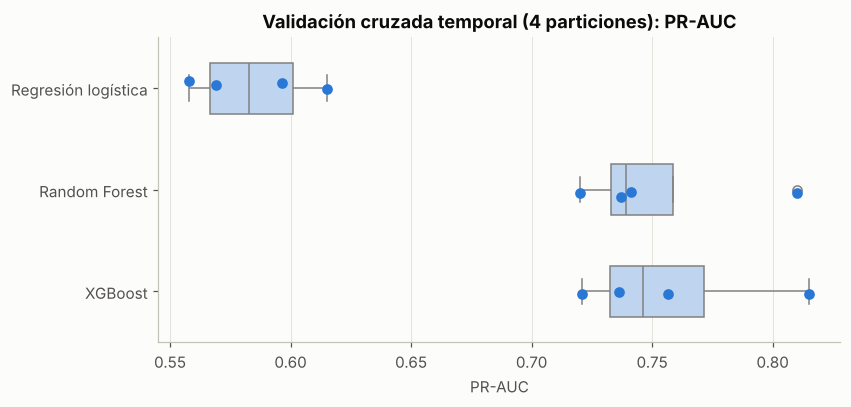

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.6))
orden = ["Regresión logística", "Random Forest", "XGBoost"]
sns.boxplot(data=cv_clf, x="PR-AUC", y="modelo", order=orden, color="#b7d3f6", width=0.5, ax=ax)
sns.stripplot(data=cv_clf, x="PR-AUC", y="modelo", order=orden, color=AZUL, size=7, ax=ax)
ax.set_title("Validación cruzada temporal (4 particiones): PR-AUC"); ax.set_ylabel("")
guardar("06_cv_clasificacion")

**Selección:** se elige el modelo con mayor **PR-AUC** promedio, la métrica más informativa cuando la clase positiva (atraso) es minoritaria. El umbral de decisión se ajusta para **maximizar F1** en la última partición de validación (periodo más reciente del entrenamiento), sin tocar el conjunto de prueba.

In [14]:
mejor_clf = resumen_cv[("PR-AUC", "mean")].idxmax()
yv, pv = oof_ultimo[mejor_clf]
prec, rec, thr = precision_recall_curve(yv, pv)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
UMBRAL = float(thr[np.argmax(f1s[:-1])])
print(f"Mejor modelo: {mejor_clf} · Umbral óptimo (F1): {UMBRAL:.2f}")

# Entrenamiento final con todo el conjunto de entrenamiento y evaluación en prueba
resultados_test, probs_test = [], {}
dummy = DummyClassifier(strategy="prior").fit(X_tr, y_tr)
for nombre, m in [("Línea base (siempre la clase mayoritaria)", dummy)] + list(modelos_clf.items()):
    if nombre in modelos_clf: m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]; probs_test[nombre] = p
    u = UMBRAL if nombre == mejor_clf else 0.5
    pred = p >= u
    resultados_test.append({"modelo": nombre, "umbral": round(u, 2), "ROC-AUC": roc_auc_score(y_te, p),
        "PR-AUC": average_precision_score(y_te, p), "Exactitud": accuracy_score(y_te, pred),
        "Precisión": precision_score(y_te, pred, zero_division=0), "Recall": recall_score(y_te, pred),
        "F1": f1_score(y_te, pred), "Brier": brier_score_loss(y_te, p)})
tabla_clf = pd.DataFrame(resultados_test).set_index("modelo").round(3)
clf_final = modelos_clf[mejor_clf]
tabla_clf

Mejor modelo: XGBoost · Umbral óptimo (F1): 0.61


,umbral,ROC-AUC,PR-AUC,Exactitud,Precisión,Recall,F1,Brier
modelo,,,,,,,,
Línea base (siempre la clase mayoritaria),0.50,0.500,0.200,0.800,0.000,0.000,0.000,0.160
Regresión logística,0.50,0.906,0.735,0.879,0.701,0.692,0.696,0.094
Random Forest,0.50,0.952,0.858,0.913,0.799,0.756,0.777,0.067
XGBoost,0.61,0.951,0.859,0.913,0.837,0.698,0.761,0.066


**Interpretación de métricas (conjunto de prueba, tareas que el modelo nunca vio):**
- **ROC-AUC ≈ 0.95**: si se toma una tarea que se atrasó y otra que no, el modelo le asigna mayor riesgo a la atrasada en el 95 % de los casos.
- **PR-AUC ≈ 0.86**, frente a 0.20 de un clasificador al azar.
- **Recall**: proporción de las tareas que realmente se atrasaron que el modelo logra anticipar. **Precisión**: de las tareas que el modelo marca como riesgo, cuántas efectivamente se atrasan.
- La **línea base** tiene exactitud cercana al 80 % pero recall 0: confirma por qué la exactitud es engañosa en este problema.

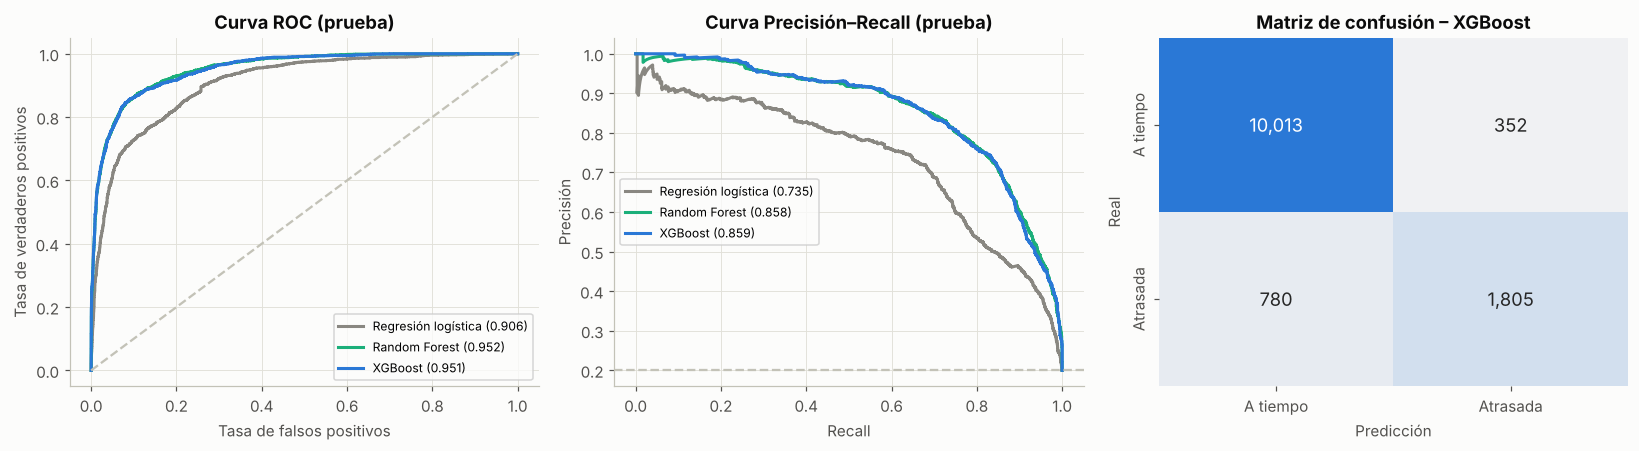

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
colores = {"Regresión logística": GRIS, "Random Forest": AQUA, "XGBoost": AZUL}
for nombre, c in colores.items():
    fpr, tpr, _ = roc_curve(y_te, probs_test[nombre]); ax[0].plot(fpr, tpr, color=c, lw=2, label=f"{nombre} ({roc_auc_score(y_te, probs_test[nombre]):.3f})")
    pr, rc, _ = precision_recall_curve(y_te, probs_test[nombre]); ax[1].plot(rc, pr, color=c, lw=2, label=f"{nombre} ({average_precision_score(y_te, probs_test[nombre]):.3f})")
ax[0].plot([0, 1], [0, 1], color="#c3c2b7", ls="--"); ax[0].set(title="Curva ROC (prueba)", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos"); ax[0].legend(fontsize=8)
ax[1].axhline(y_te.mean(), color="#c3c2b7", ls="--"); ax[1].set(title="Curva Precisión–Recall (prueba)", xlabel="Recall", ylabel="Precisión"); ax[1].legend(fontsize=8)
cm = confusion_matrix(y_te, probs_test[mejor_clf] >= UMBRAL)
sns.heatmap(cm, annot=True, fmt=",", cmap=sns.light_palette(AZUL, as_cmap=True), cbar=False, ax=ax[2],
            xticklabels=["A tiempo", "Atrasada"], yticklabels=["A tiempo", "Atrasada"], annot_kws={"size": 12})
ax[2].set(title=f"Matriz de confusión – {mejor_clf}", xlabel="Predicción", ylabel="Real"); ax[2].grid(False)
plt.tight_layout(); guardar("07_evaluacion_clasificacion")

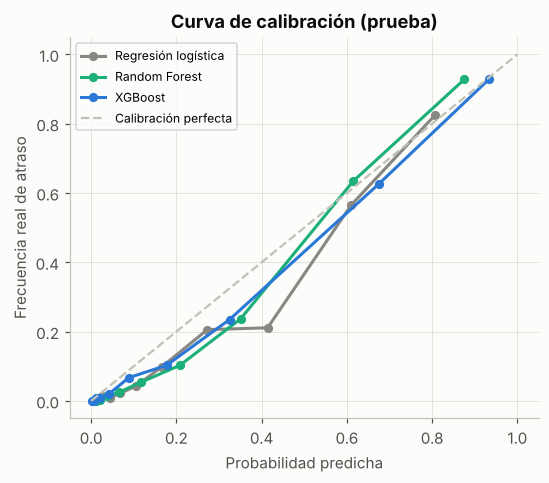

In [16]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for nombre, c in colores.items():
    fr, mp = calibration_curve(y_te, probs_test[nombre], n_bins=10, strategy="quantile")
    ax.plot(mp, fr, marker="o", ms=5, color=c, lw=2, label=nombre)
ax.plot([0, 1], [0, 1], color="#c3c2b7", ls="--", label="Calibración perfecta")
ax.set(title="Curva de calibración (prueba)", xlabel="Probabilidad predicha", ylabel="Frecuencia real de atraso"); ax.legend(fontsize=8)
guardar("08_calibracion")

**Calibración:** las curvas cercanas a la diagonal indican que cuando el modelo dice "70 % de riesgo", aproximadamente el 70 % de esas tareas se atrasa. Es una condición necesaria para que la simulación del cronograma en la app sea confiable.

## 6. Interpretación del modelo con SHAP: ¿qué causa los atrasos?

SHAP (*SHapley Additive exPlanations*, Lundberg y Lee, 2017) asigna a cada variable su contribución al riesgo de **cada** tarea. Así el modelo deja de ser una "caja negra" y puede explicar **por qué** una tarea está en riesgo. Esta explicación es la que muestra la app.

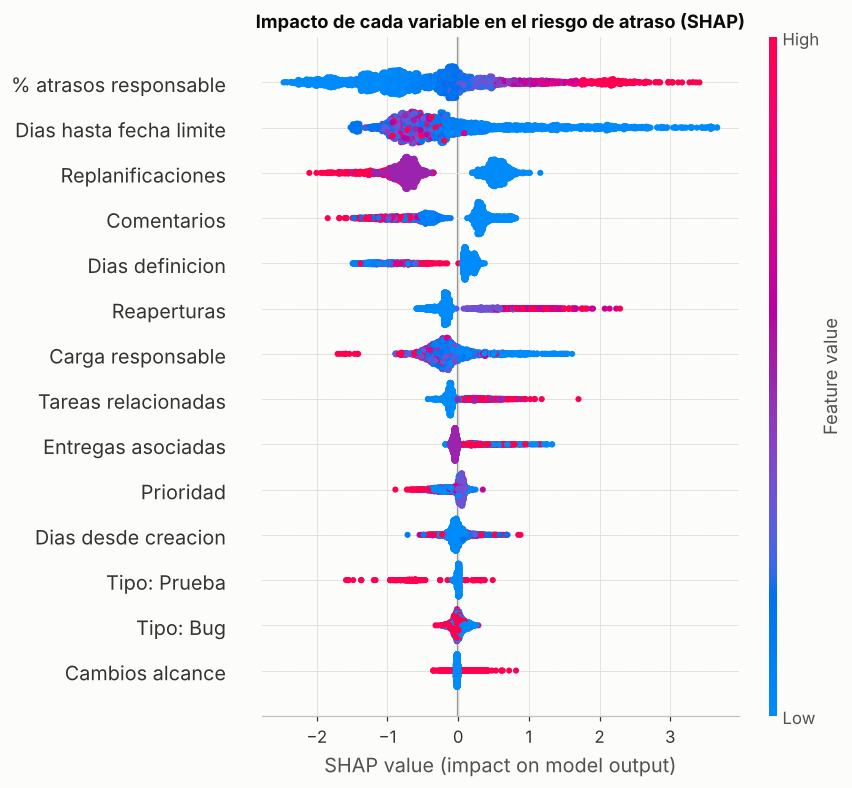

In [17]:
muestra = X_te.sample(3000, random_state=SEMILLA)
modelo_arbol = clf_final if mejor_clf != "Regresión logística" else modelos_clf["XGBoost"]
explainer = shap.TreeExplainer(modelo_arbol)
sv = explainer.shap_values(muestra)
sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv)
nombres = [nombre_legible(c) for c in muestra.columns]
plt.figure(); shap.summary_plot(sv, muestra, feature_names=nombres, max_display=14, show=False)
plt.title("Impacto de cada variable en el riesgo de atraso (SHAP)"); guardar("09_shap_resumen")

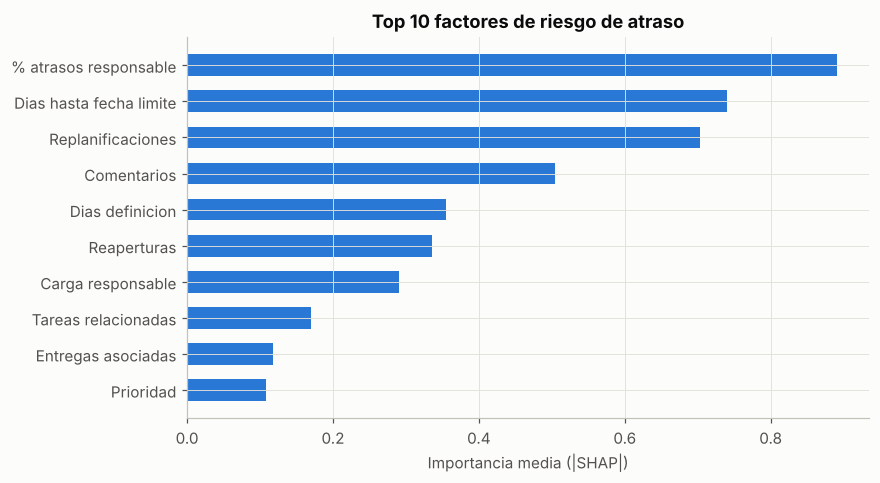

,variable,SHAP medio |abs|
0,% atrasos responsable,0.890429
1,Dias hasta fecha limite,0.740096
2,Replanificaciones,0.702465
3,Comentarios,0.504502
4,Dias definicion,0.355154
5,Reaperturas,0.335245
6,Carga responsable,0.290070
7,Tareas relacionadas,0.169936
8,Entregas asociadas,0.117630
9,Prioridad,0.107912


In [18]:
importancia = (pd.DataFrame({"variable": nombres, "SHAP medio |abs|": np.abs(sv).mean(0)})
               .sort_values("SHAP medio |abs|", ascending=False).reset_index(drop=True))
fig, ax = plt.subplots(figsize=(8, 4.5))
top = importancia.head(10).iloc[::-1]
ax.barh(top.variable, top["SHAP medio |abs|"], color=AZUL, height=0.6)
ax.set_title("Top 10 factores de riesgo de atraso"); ax.set_xlabel("Importancia media (|SHAP|)")
guardar("10_importancia")
importancia.head(10)

**Cómo leer el gráfico:** cada punto es una tarea. El color indica el valor de la variable (rojo = alto, azul = bajo) y la posición indica si empuja el riesgo hacia arriba (derecha) o hacia abajo (izquierda).

**Lectura para la gestión de proyectos:**
1. **% histórico de atrasos del responsable** (rojo a la derecha): es el factor más influyente. Más que juzgar a la persona, revela patrones recurrentes de sobrecompromiso o de tipo de trabajo.
2. **Días hasta la fecha límite** (azul a la derecha): poca holgura dispara el riesgo.
3. **Replanificaciones, comentarios y días de definición** (rojo a la izquierda): más actividad de seguimiento **reduce** el riesgo. Una tarea "silenciosa", sin comentarios ni ajustes, es una alerta temprana de abandono.
4. **Reaperturas** (rojo a la derecha): el **retrabajo**, uno de los desperdicios Lean, aumenta el riesgo de atraso.
5. **Tareas relacionadas / dependencias** (rojo a la derecha): más vínculos implican más coordinación y más riesgo.

**Acciones que sugiere el modelo:** dar holgura realista a las fechas, revisar tareas sin seguimiento, atacar las causas de retrabajo y vigilar a los responsables con historial de atrasos (por ejemplo, ajustando su carga o su forma de estimar).

## 7. Modelo 2 – Regresión: si se atrasa, ¿cuántos días?

Se entrena **solo con tareas atrasadas**, con objetivo `log(1 + días)`. Combinado con el modelo 1:

> **Atraso esperado = P(atraso) × días estimados si ocurre**

Modelos comparados: línea base (mediana histórica), Ridge (lineal regularizado), Random Forest y XGBoost.

In [19]:
m_tr, m_te = y_tr == 1, y_te == 1
Xr_tr, Xr_te = X_tr[m_tr], X_te[m_te]
dias = df.dias_atraso.values
yr_tr, yr_te = dias[:corte][m_tr], dias[corte:][m_te]
modelos_reg = {
    "Ridge": make_pipeline(log1p_tf, StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=10, n_jobs=-1, random_state=SEMILLA),
    "XGBoost": XGBRegressor(n_estimators=600, max_depth=4, learning_rate=0.03, subsample=0.8,
                            colsample_bytree=0.8, min_child_weight=5, n_jobs=-1, random_state=SEMILLA),
}
filas, residuos_cv = [], {}
for k, (a, b) in enumerate(tscv.split(Xr_tr)):
    base = np.median(yr_tr[a])
    filas.append({"modelo": "Línea base (mediana)", "particion": k+1, "MAE": mean_absolute_error(yr_tr[b], np.full(len(b), base)),
                  "MedAE": median_absolute_error(yr_tr[b], np.full(len(b), base))})
    for nombre, m in modelos_reg.items():
        m.fit(Xr_tr.iloc[a], np.log1p(yr_tr[a])); lp = m.predict(Xr_tr.iloc[b]); pr = np.expm1(lp)
        filas.append({"modelo": nombre, "particion": k+1, "MAE": mean_absolute_error(yr_tr[b], pr), "MedAE": median_absolute_error(yr_tr[b], pr)})
        residuos_cv.setdefault(nombre, []).append(np.log1p(yr_tr[b]) - lp)
cv_reg = pd.DataFrame(filas)
cv_reg.groupby("modelo")[["MAE", "MedAE"]].agg(["mean", "std"]).round(1)

MAE       MedAE     
                      mean   std  mean  std
modelo                                     
Línea base (mediana)  75.6  14.9  24.2  1.5
Random Forest         72.2  15.9  23.8  1.9
Ridge                 76.1  15.0  26.9  5.2
XGBoost               72.2  16.9  24.4  3.2

In [20]:
mejor_reg = cv_reg[cv_reg.modelo != "Línea base (mediana)"].groupby("modelo").MedAE.mean().idxmin()
SIGMA_LOG = float(np.std(np.concatenate(residuos_cv[mejor_reg])))
filas = []
base = np.median(yr_tr)
filas.append({"modelo": "Línea base (mediana)", "MAE": mean_absolute_error(yr_te, np.full(len(yr_te), base)),
              "MedAE": median_absolute_error(yr_te, np.full(len(yr_te), base)), "RMSE": mean_squared_error(yr_te, np.full(len(yr_te), base))**0.5,
              "R² (log)": 0.0, "Spearman": np.nan})
pred_reg = {}
for nombre, m in modelos_reg.items():
    m.fit(Xr_tr, np.log1p(yr_tr)); lp = m.predict(Xr_te); pr = np.expm1(lp); pred_reg[nombre] = pr
    filas.append({"modelo": nombre, "MAE": mean_absolute_error(yr_te, pr), "MedAE": median_absolute_error(yr_te, pr),
                  "RMSE": mean_squared_error(yr_te, pr)**0.5, "R² (log)": r2_score(np.log1p(yr_te), lp), "Spearman": spearmanr(yr_te, pr)[0]})
tabla_reg = pd.DataFrame(filas).set_index("modelo").round(3)
reg_final = modelos_reg[mejor_reg]
print(f"Mejor regresor: {mejor_reg} · Desviación del error (escala log): {SIGMA_LOG:.2f}")
tabla_reg

Mejor regresor: Random Forest · Desviación del error (escala log): 1.50


,MAE,MedAE,RMSE,R² (log),Spearman
modelo,,,,,
Línea base (mediana),32.133,22.000,51.484,0.000,NaN
Ridge,30.083,17.271,50.904,0.033,0.268
Random Forest,30.003,14.606,51.571,0.074,0.397
XGBoost,28.016,14.206,49.817,0.134,0.448


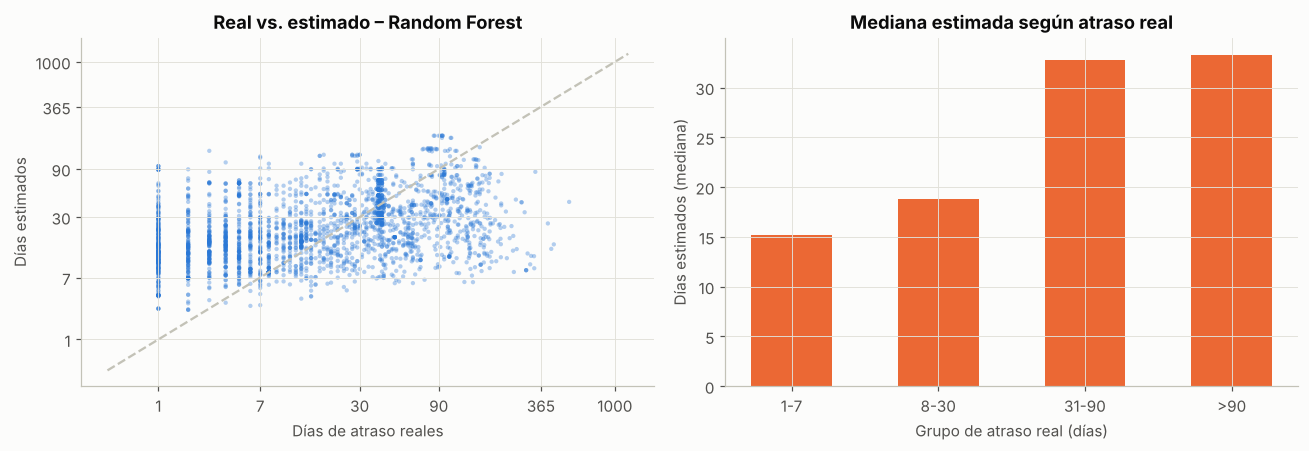

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
pr = pred_reg[mejor_reg]
ax[0].scatter(np.log1p(yr_te), np.log1p(pr), s=8, alpha=0.35, color=AZUL, edgecolor="none")
lim = [0, np.log1p(1200)]; ax[0].plot(lim, lim, color="#c3c2b7", ls="--")
tk = [1, 7, 30, 90, 365, 1000]
for f in (ax[0].set_xticks, ax[0].set_yticks): f(np.log1p(tk))
ax[0].set_xticklabels(tk); ax[0].set_yticklabels(tk)
ax[0].set(title=f"Real vs. estimado – {mejor_reg}", xlabel="Días de atraso reales", ylabel="Días estimados")
grupos = pd.cut(yr_te, [0, 7, 30, 90, 1e5], labels=["1-7", "8-30", "31-90", ">90"])
med = pd.DataFrame({"g": grupos, "p": pr}).groupby("g", observed=True).p.median()
ax[1].bar(med.index.astype(str), med.values, color=NARANJA, width=0.55)
ax[1].set(title="Mediana estimada según atraso real", xlabel="Grupo de atraso real (días)", ylabel="Días estimados (mediana)")
plt.tight_layout(); guardar("11_regresion")

**Interpretación honesta:** predecir **cuántos** días se atrasará una tarea es bastante más difícil que predecir **si** se atrasará. La magnitud depende de eventos que no están en los datos (cambios de prioridad del negocio, ausencias, dependencias externas), y eso coincide con la literatura.
- En la validación cruzada, los modelos apenas superan a la línea base (error mediano ≈ 24 días en ambos casos). En el conjunto de prueba la mejora es mayor: el error mediano baja de 22 a unos 14–15 días.
- El modelo **ordena** parcialmente los atrasos (Spearman ≈ 0.40): estima atrasos mayores para tareas que efectivamente se atrasan más, pero con mucha dispersión (R² bajo).

**Consecuencia de diseño:** la app no da un único número de días, sino **rangos**. Simula muchos escenarios con una incertidumbre explícita, y el pronóstico se apoya sobre todo en el **modelo de clasificación**, que es el más confiable.

## 8. Análisis de robustez: ¿el modelo funciona igual en todas las organizaciones?

In [22]:
te = df.iloc[corte:].assign(p=probs_test[mejor_clf])
por_org = (te.groupby("proyecto").apply(lambda g: pd.Series({
            "tareas": len(g), "% atrasadas": g.atrasada.mean()*100,
            "ROC-AUC": roc_auc_score(g.atrasada, g.p) if g.atrasada.nunique() > 1 else np.nan,
            "PR-AUC": average_precision_score(g.atrasada, g.p) if g.atrasada.nunique() > 1 else np.nan}))
           .round(3).sort_values("ROC-AUC"))
por_org

,tareas,% atrasadas,ROC-AUC,PR-AUC
proyecto,,,,
jboss,223.0,69.507,0.668,0.834
apache,993.0,64.753,0.748,0.827
mulesoft,2968.0,10.445,0.904,0.693
javanet,2747.0,21.478,0.913,0.761
wso2,751.0,31.158,0.955,0.909
duraspace,701.0,28.103,0.965,0.948
moodle,4561.0,9.910,0.993,0.970
jira,6.0,66.667,1.000,1.000


**Lectura:** el modelo mantiene un buen desempeño en las distintas organizaciones, aunque varía según el contexto. Esto respalda dos decisiones de diseño de la app: (1) usar el modelo general como punto de partida y (2) permitir que cada equipo aporte **su propio historial** (por ejemplo, el % de atrasos de cada responsable, calculado a partir de sus tareas cerradas) para adaptar las predicciones a su realidad.

## 9. Exportación de modelos para la aplicación

In [23]:
joblib.dump(clf_final, MOD / "clasificador.joblib", compress=3)
joblib.dump(reg_final, MOD / "regresor.joblib", compress=3)
fila_clf, fila_reg = tabla_clf.loc[mejor_clf], tabla_reg.loc[mejor_reg]
metadata = {
    "modelo_clasificacion": mejor_clf, "modelo_regresion": mejor_reg,
    "umbral": round(UMBRAL, 4), "sigma_log": round(SIGMA_LOG, 4),
    "pct_atrasos_mediana": float(df.pct_atrasos_responsable.median()),
    "columnas": COLUMNAS_MODELO,
    "n_tareas": int(len(df)), "n_entrenamiento": int(corte), "n_prueba": int(len(df) - corte),
    "pct_atrasadas": round(float(df.atrasada.mean()) * 100, 1),
    "metricas_clasificacion": {k: round(float(v), 3) for k, v in fila_clf.items()},
    "metricas_regresion": {k: round(float(v), 3) for k, v in fila_reg.items()},
    "baseline_regresion_medae": round(float(tabla_reg.loc["Línea base (mediana)", "MedAE"]), 1),
    "importancia": importancia.head(10).round(4).to_dict(orient="records"),
    "cv_clasificacion": {m: {k: round(float(resumen_cv.loc[m, (k, "mean")]), 3) for k in ["ROC-AUC", "PR-AUC", "F1@0.5"]} for m in resumen_cv.index},
    "test_clasificacion": tabla_clf.reset_index().to_dict(orient="records"),
    "test_regresion": tabla_reg.reset_index().fillna(0).to_dict(orient="records"),
}
(MOD / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
tabla_clf.to_csv(ROOT / "reports" / "metricas_clasificacion.csv")
tabla_reg.to_csv(ROOT / "reports" / "metricas_regresion.csv")
resumen_cv.to_csv(ROOT / "reports" / "cv_clasificacion.csv")
por_org.to_csv(ROOT / "reports" / "metricas_por_organizacion.csv")
print(json.dumps({k: metadata[k] for k in ["modelo_clasificacion", "modelo_regresion", "umbral", "sigma_log"]}, ensure_ascii=False))

{"modelo_clasificacion": "XGBoost", "modelo_regresion": "Random Forest", "umbral": 0.6135, "sigma_log": 1.4987}


## 10. Aplicación a un cronograma: el prototipo en acción

Se carga un cronograma de ejemplo (`data/ejemplo_cronograma.xlsx`): un **portal de autogestión para clientes** con 20 tareas, 6 responsables y dependencias. El plan termina el 12/02/2027 y la fecha **comprometida con el patrocinador** es el **12/03/2027** (cuatro semanas de holgura). La fecha de corte simulada es el **1 de diciembre de 2026**. El módulo `src/cronograma.py`, que es el mismo que usa la app:
1. Calcula las variables del modelo para cada tarea abierta.
2. Predice la probabilidad y los días de atraso.
3. Simula 2,000 escenarios del proyecto propagando los atrasos por las dependencias (Monte Carlo).
4. Prioriza las tareas que más ponen en riesgo la fecha final.

**Parámetro de incertidumbre.** La desviación del error del regresor (`SIGMA_LOG` ≈ 1.5 en escala log) refleja la enorme variabilidad de los proyectos open source, donde hay tareas que se atrasan años. Al sumar atrasos en cadena, ese nivel produciría escenarios irreales para un cronograma corporativo de semanas. Por eso la simulación usa por defecto una **incertidumbre media (σ = 0.6)**, recorta los escenarios extremos (±1.5σ, máximo 180 días por tarea) y la app permite ajustar ambos parámetros.

In [24]:
from src.cronograma import preparar_cronograma, calcular_variables, predecir, simular, priorizar
FECHA_CORTE = pd.Timestamp("2026-12-01")
cron = preparar_cronograma(pd.read_excel(ROOT / "data" / "ejemplo_cronograma.xlsx", sheet_name="cronograma"))
var = calcular_variables(cron, FECHA_CORTE, metadata["pct_atrasos_mediana"])
pred = predecir(var, clf_final, reg_final)
SIGMA_APP = 0.6
FECHA_COMPROMISO = pd.Timestamp("2027-03-12")
sim = simular(pred, FECHA_CORTE, SIGMA_APP, n=2000, fecha_compromiso=FECHA_COMPROMISO)
print(f"Fin según el plan: {sim['fin_cronograma']:%d/%m/%Y} · Fecha comprometida: {sim['fin_planificado']:%d/%m/%Y}")
print(f"Probabilidad de cumplirla: {sim['prob_cumplir']:.0%}")
print(f"Fecha probable (P50): {sim['p50']:%d/%m/%Y} · Fecha segura (P80): {sim['p80']:%d/%m/%Y}")
prio = priorizar(pred, sim["criticidad"])
prio[["id", "tarea", "responsable", "prob_atraso", "dias_atraso_si_ocurre", "criticidad", "puntaje_atencion"]].head(8).round(2)

Fin según el plan: 12/02/2027 · Fecha comprometida: 12/03/2027
Probabilidad de cumplirla: 22%
Fecha probable (P50): 30/03/2027 · Fecha segura (P80): 25/04/2027


,id,tarea,responsable,prob_atraso,dias_atraso_si_ocurre,criticidad,puntaje_atencion
7,8,Módulo de solicitudes en línea,María Rodríguez,0.64,21.83,0.76,17.68
6,7,Integración con core (API),Carlos Méndez,0.90,12.85,0.95,16.63
16,17,Salida a producción,Carlos Méndez,0.22,20.71,0.97,6.69
9,10,Seguridad y autenticación (2FA),Carlos Méndez,0.58,17.39,0.11,6.08
15,16,Capacitación a agentes,Ana Pérez,0.21,25.54,0.21,3.72
13,14,Pruebas de aceptación con usuarios,Ana Pérez,0.10,25.19,0.76,3.26
5,6,Módulo de consulta de productos,José Martínez,0.39,14.10,0.02,2.87
8,9,Notificaciones por correo y SMS,José Martínez,0.20,23.27,0.10,2.79


**Lectura del ejemplo:** aunque el plan tiene cuatro semanas de holgura, la probabilidad de cumplir la fecha comprometida es baja (≈22 %). Las dos tareas que encabezan la lista de atención forman una cadena:
- **Integración con el core (API)**: 90 % de riesgo y en la cadena crítica en ~95 % de los escenarios. De ella dependen otras tres tareas.
- **Módulo de solicitudes en línea**: depende de la integración, tiene 64 % de riesgo y el atraso estimado más largo.

Esa cadena es el **cuello de botella** del proyecto. Ahí debe concentrar sus acciones el gerente: más capacidad, dividir la integración en entregas parciales o adelantar pruebas con el core. En cambio, tareas como el manual de usuario o el tablero de métricas tienen poco impacto en la fecha final aunque se atrasen.

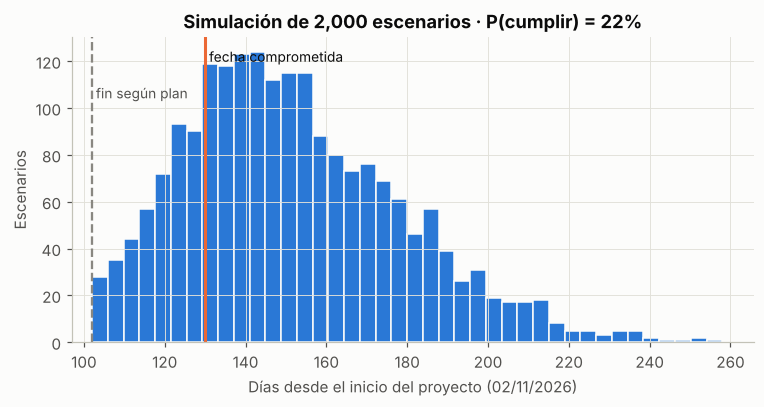

In [25]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(sim["fin_proyecto_dias"], bins=40, color=AZUL, edgecolor="#fcfcfb")
ax.axvline(sim["fin_planificado_dias"], color=NARANJA, lw=2)
ax.text(sim["fin_planificado_dias"], ax.get_ylim()[1]*0.92, " fecha comprometida", color="#0b0b0b", fontsize=9)
plan = (sim["fin_cronograma"] - sim["origen"]).days
ax.axvline(plan, color=GRIS, lw=1.5, ls="--"); ax.text(plan, ax.get_ylim()[1]*0.80, " fin según plan", color="#52514e", fontsize=9)
ax.set_xlim(min(plan, sim["fin_proyecto_dias"].min()) - 5, None)
ax.set(title=f"Simulación de 2,000 escenarios · P(cumplir) = {sim['prob_cumplir']:.0%}",
       xlabel=f"Días desde el inicio del proyecto ({sim['origen']:%d/%m/%Y})", ylabel="Escenarios")
guardar("12_montecarlo_ejemplo")

## 11. Conclusiones

1. **Coherencia problema–solución:** sí es posible anticipar con alta capacidad discriminativa (ROC-AUC ≈ 0.95 en tareas futuras) qué tareas de un cronograma se atrasarán, usando solo información disponible al momento de comprometer la fecha.
2. **Modelos:** los ensambles de árboles superan a la regresión logística, lo que confirma relaciones **no lineales**: el efecto de la holgura no es proporcional, porque el riesgo se dispara cuando faltan 0–1 días.
3. **Magnitud del atraso:** estimar los días es mucho más incierto (mejora modesta frente a la línea base). Por eso el prototipo comunica **rangos y probabilidades** (P50, P80) en lugar de una sola fecha, en línea con el pronóstico probabilístico de proyectos. Además ofrece un factor de ajuste para adaptar las magnitudes al contexto de cada organización.
4. **Factores accionables:** holgura de las fechas, historial del responsable, retrabajo (reaperturas), dependencias y, sobre todo, el **nivel de seguimiento**: las tareas sin actividad son las que más se atrasan. Son palancas que un gerente de proyecto puede gestionar.
5. **Limitaciones:** los datos provienen de proyectos de software de código abierto. Al aplicarlo en otros contextos (por ejemplo, banca o educación), las predicciones deben tomarse como **orientativas** y recalibrarse con el historial propio. Variables como la carga del responsable pueden tener escalas distintas en equipos pequeños.
6. **Trabajo futuro:** reentrenar con historial propio de la organización, incorporar texto de las tareas (NLP) y conectar la app directamente con Jira, Azure DevOps o Planner.